<a href="https://colab.research.google.com/github/TreesaAbraham/svd-image-compression-MATH344L/blob/main/notebook/03_images_compress_SVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#Milestone 3

In [3]:
import os
import subprocess
import sys

USER = "TreesaAbraham"
REPO = "svd-image-compression-MATH344L"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
        check=True)

sys.path.insert(0, f"{REPO}/src")
from compress import rank_k_approx

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

A = data.camera().astype(float)
m, n = A.shape
T = data.text().astype(float)
print("Camera:", A.shape, "Text:", T.shape)

Camera: (512, 512) Text: (172, 448)


Loads the grayscale images camera and text and turns them into floating point matrices

In [5]:
def storage(m, n, k):
#Number of values needed to store a rank-k approximation.
  return k * (m + n + 1)
def compression_ratio(m, n, k):
#Original number of values divided by compressed number of values.
  return (m * n) / storage(m, n, k)
print("Original camera values:", m * n)
for k in [1, 10, 50, 100, 255, 256]:
  print(f"k={k:3d} stored={storage(m, n, k):6d}"
f"ratio={compression_ratio(m, n, k):.2f}")

Original camera values: 262144
k=  1 stored=  1025ratio=255.75
k= 10 stored= 10250ratio=25.58
k= 50 stored= 51250ratio=5.12
k=100 stored=102500ratio=2.56
k=255 stored=261375ratio=1.00
k=256 stored=262400ratio=1.00


Defines the function to eval the count-based storage savings of the approx. Compression ratio function compares it to the original, where a ratio greater than 1 is memory savings

In [6]:
#part c

def rel_error(A, B):
  #relative Frobenius error when B approximates A
  return np.linalg.norm(A-B) / np.linalg.norm(A)

for k in [1, 5, 20, 50, 100]:
  Ak = rank_k_approx(A, k)
  print(f"k={k:3d} relative error={rel_error(A, Ak):.4f}")

k=  1 relative error=0.3604
k=  5 relative error=0.1720
k= 20 relative error=0.1012
k= 50 relative error=0.0636
k=100 relative error=0.0393


We measure the relative Frobenius error when B approximates A across the different ranks k. As the rank increases, the error decreases.

In [7]:
#part D

U, s, Vt = np.linalg.svd(A, full_matrices = False)

def predicted_error(s, k):
  #relative rank-k error computed from the singular values
  return np.sqrt(np.sum(s[k:]**2) / np.sum(s**2))

for k in [1, 5, 20, 50, 100]:
  actual = rel_error(A, rank_k_approx(A, k))
  predicted = predicted_error(s, k)
  print(f"k={k:3d} actual={actual:.6f} predicted={predicted:.6f}")



k=  1 actual=0.360449 predicted=0.360449
k=  5 actual=0.172014 predicted=0.172014
k= 20 actual=0.101208 predicted=0.101208
k= 50 actual=0.063565 predicted=0.063565
k=100 actual=0.039329 predicted=0.039329


We calculate the predicted error from the singular values instead of having to reconstruct the full matrix at each rank, this should be the same which is what we see

In [8]:
#part e

ks = np.arange(1, len(s) + 1)
errors = np.array([predicted_error(s,k) for k in ks])
for target in [0.10, 0.05, 0.02, 0.01]:
  k = ks[errors <= target][0]
  ratio = compression_ratio(m, n, k)
  print(f"k={k}, ratio={ratio:.2f}")

k=21, ratio=12.18
k=73, ratio=3.50
k=186, ratio=1.38
k=263, ratio=0.97


This automates finding the optimal rank k, identifying all qualifying ranks and then selecting the smallest rank

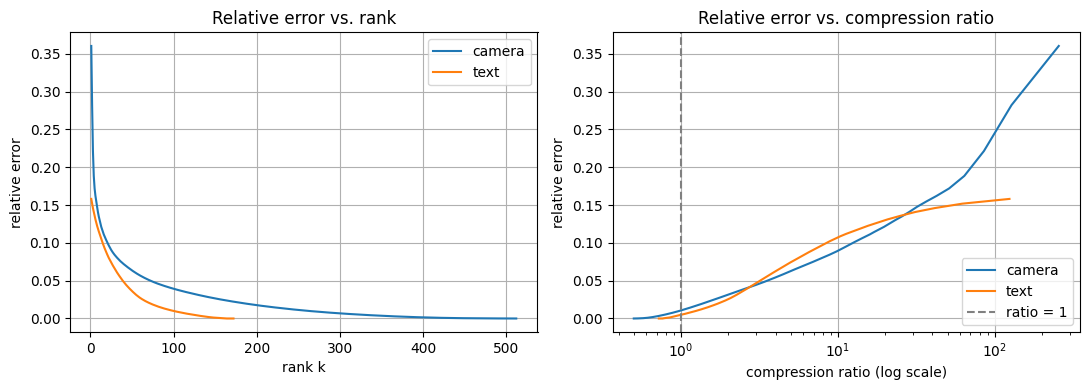

In [9]:
#part F

images = {"camera": A, "text": T}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, M in images.items():
  m_img, n_img = M.shape
  s_img = np.linalg.svd(M, compute_uv=False)
  ranks = np.arange(1, len(s_img) + 1)
  errs = [predicted_error(s_img, k) for k in ranks]
  ratios = [compression_ratio(m_img, n_img, k) for k in ranks]
  ax1.plot(ranks, errs, label=name)
  ax2.semilogx(ratios, errs, label=name)
ax1.set_title("Relative error vs. rank")
ax1.set_xlabel("rank k")
ax1.set_ylabel("relative error")
ax2.axvline(1, color="gray", linestyle="--", label="ratio = 1")
ax2.set_title("Relative error vs. compression ratio")
ax2.set_xlabel("compression ratio (log scale)")
ax2.set_ylabel("relative error")
for ax in (ax1, ax2):
  ax.grid()
  ax.legend()
plt.tight_layout()
plt.savefig("error_vs_ratio.png", dpi=150)
plt.show()

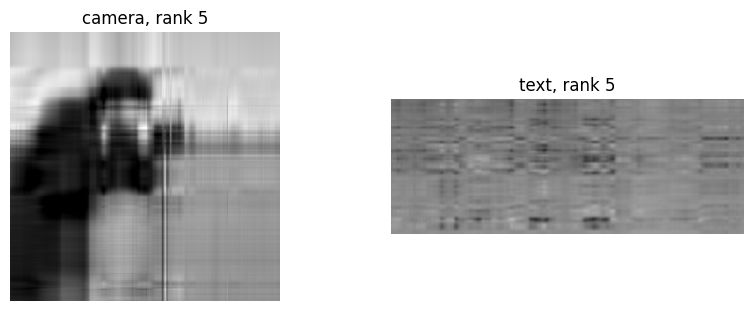

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, M) in zip(axes, images.items()):
  Mk = np.clip(rank_k_approx(M, 5), 0, 255)
  ax.imshow(Mk, cmap="gray", vmin=0, vmax=255)
  ax.set_title(f"{name}, rank 5")
  ax.axis("off")
plt.show()

We're plotting relative error against rank k and compression ratio on a log scale

In [11]:
#part G

A20 = rank_k_approx(A, 20)
outside = (A20 < 0) | (A20 > 255)
print("Out-of-range pixels:", outside.sum())
print("Fraction", f"{outside.mean():.1%}")
print("Error before clipping:", round(rel_error(A, A20), 4))
print("Error after clipping:",
      round(rel_error(A, np.clip(A20, 0, 255)), 4))

Out-of-range pixels: 2634
Fraction 1.0%
Error before clipping: 0.1012
Error after clipping: 0.1008


We look at the out-of-range pixels and the effect of clipping vaues

In [12]:
#part H

from google.colab import files
from PIL import Image

uploaded = files.upload()

Saving generated-image.png to generated-image.png


In [13]:
name = list(uploaded)[0]

img = Image.open(name). convert("L") #opens the chosen file and converts it to grayscale
img.thumbnail((800,800)) #sets size to make it viewable and small enough for Colab while maintaining proportions
P = np.array(img)

(np.float64(-0.5), np.float64(799.5), np.float64(624.5), np.float64(-0.5))

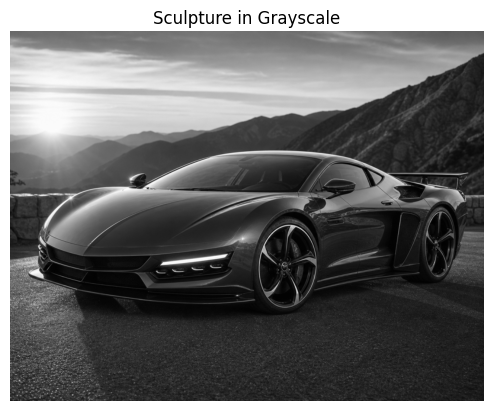

In [14]:
plt.imshow(P, cmap = "gray", vmin = 0, vmax = 255)
plt.title("Vehicle in Grayscale")
plt.axis("off")

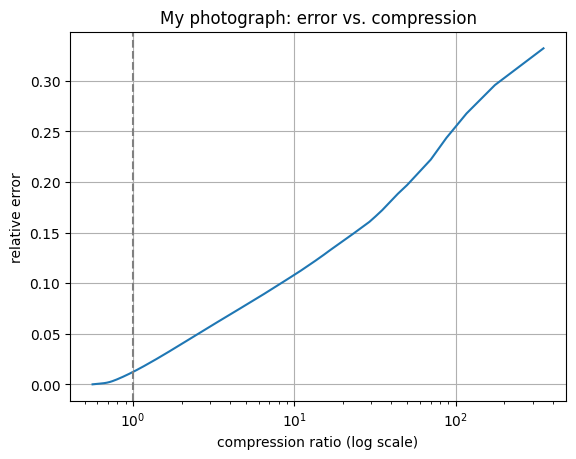

In [17]:
P_float = P.astype(float)
sp = np.linalg.svd(P_float, compute_uv=False)
kp = np.arange(1, len(sp) + 1)
ep = [predicted_error(sp, k) for k in kp]
mp, npix = P_float.shape
rp = [compression_ratio(mp, npix, k) for k in kp]
plt.semilogx(rp, ep)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("compression ratio (log scale)")
plt.ylabel("relative error")
plt.title("My photograph: error vs. compression")
plt.grid()
plt.show()

Chosen rank k: 50
Relative Error: 0.0923
Compression Ratio: 7.01


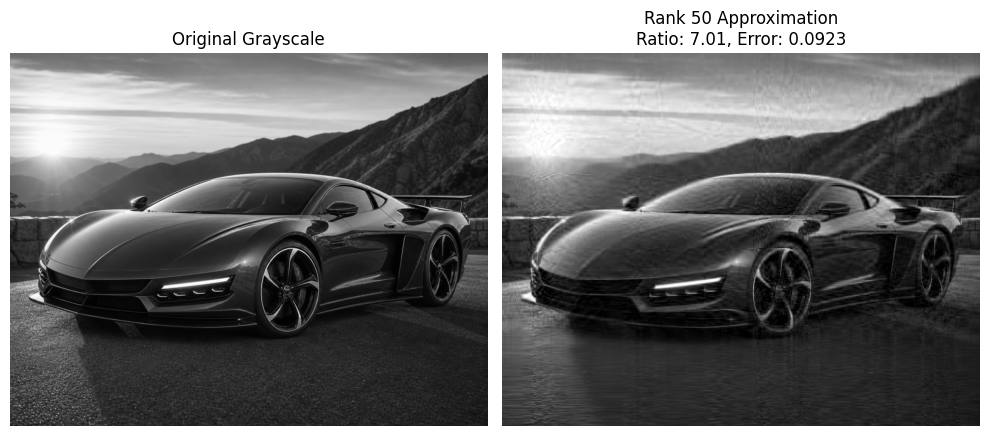

In [16]:
chosen_k = 50
P_k = np.clip(rank_k_approx(P_float, chosen_k), 0, 255)

error_val = rel_error(P_float, P_k)
ratio_val = compression_ratio(mp, npix, chosen_k)

print(f"Chosen rank k: {chosen_k}")
print(f"Relative Error: {error_val:.4f}")
print(f"Compression Ratio: {ratio_val:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10,5))

axes[0].imshow(P, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Grayscale")
axes[0].axis("off")

axes[1].imshow(P_k, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Rank {chosen_k} Approximation\nRatio: {ratio_val:.2f}, Error: {error_val:.4f}")
axes[1].axis("off")

plt.tight_layout()
plt.show()


This loads our own picture, converts to grayscale, and then plots its trade-off curve between rel error and compression ratio. We chose rank k = 50 which gets us an error less than 10% and gives a 7.01x reduction in stored values